In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [4]:
# Cargar la imagen desde la carpeta data
imagen = cv2.imread("data/Lena.png")

# Verificar si la imagen se cargó correctamente
if imagen is None:
    print("Error: no se pudo cargar la imagen")
else:
    print("Imagen cargada correctamente")

# Consultar las dimensiones de la imagen
print("Dimensiones:", imagen.shape)

Imagen cargada correctamente
Dimensiones: (512, 512, 3)


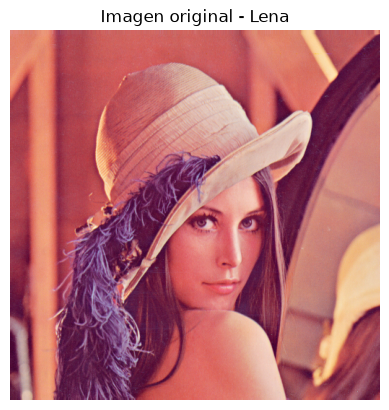

In [5]:
# Convertir de BGR a RGB para visualizar correctamente
imagen_rgb = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)

# Mostrar la imagen
plt.imshow(imagen_rgb)
plt.title("Imagen original - Lena")
plt.axis("off")
plt.show()

In [6]:
# Consultar el píxel ubicado en la fila 100 y columna 100
pixel = imagen[100, 100]

# Mostrar sus valores
print("Valores BGR:", pixel)

# Separar los tres canales
azul, verde, rojo = pixel

print("Azul:", azul)
print("Verde:", verde)
print("Rojo:", rojo)

Valores BGR: [ 78  68 178]
Azul: 78
Verde: 68
Rojo: 178


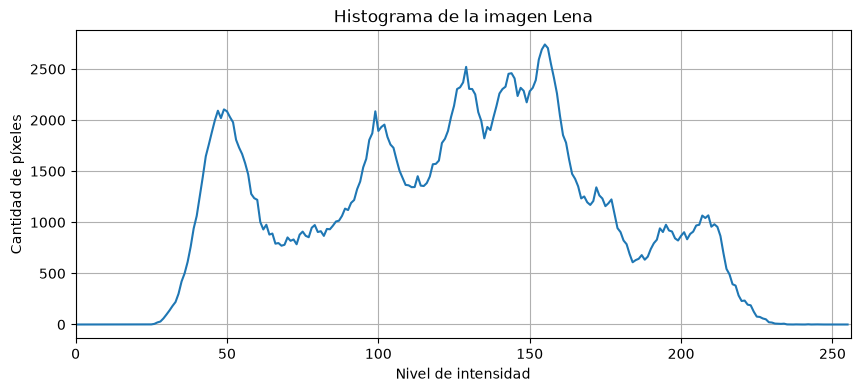

In [7]:
# Convertir la imagen original a escala de grises
imagen_gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)

# Calcular el histograma de intensidades
histograma = cv2.calcHist([imagen_gris], [0], None, [256], [0, 256])

# Representar el histograma
plt.figure(figsize=(10, 4))
plt.plot(histograma)
plt.title("Histograma de la imagen Lena")
plt.xlabel("Nivel de intensidad")
plt.ylabel("Cantidad de píxeles")
plt.xlim([0, 256])
plt.grid()
plt.show()

In [8]:
# Obtener la intensidad mínima y máxima
intensidad_minima = np.min(imagen_gris)
intensidad_maxima = np.max(imagen_gris)

# Calcular el rango dinámico
rango_dinamico = intensidad_maxima - intensidad_minima

# Mostrar los resultados
print("Intensidad mínima:", intensidad_minima)
print("Intensidad máxima:", intensidad_maxima)
print("Rango dinámico:", rango_dinamico)

Intensidad mínima: 25
Intensidad máxima: 245
Rango dinámico: 220


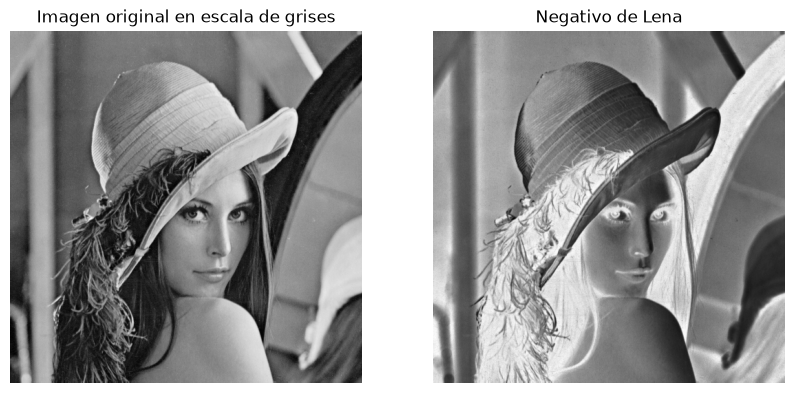

True

In [9]:
# Calcular el negativo de la imagen en escala de grises
imagen_negativa = 255 - imagen_gris

# Mostrar la imagen original y su negativo
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(imagen_gris, cmap="gray")
plt.title("Imagen original en escala de grises")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imagen_negativa, cmap="gray")
plt.title("Negativo de Lena")
plt.axis("off")

plt.show()

# Guardar el resultado
cv2.imwrite("resultados/03_negativo.png", imagen_negativa)

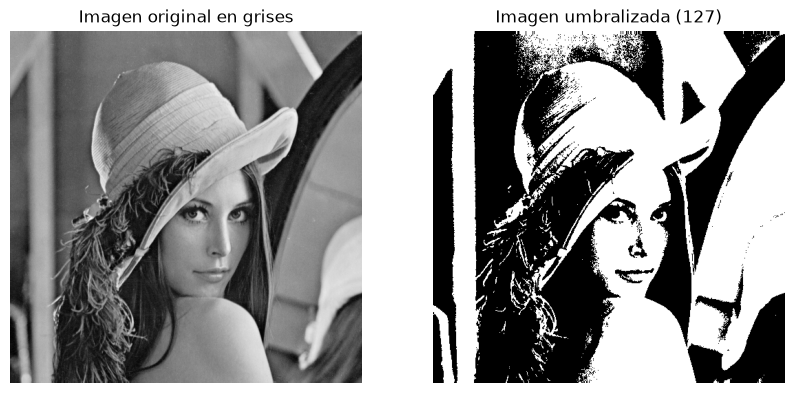

True

In [10]:
# Definir el valor del umbral
umbral = 127

# Aplicar la umbralización
_, imagen_umbralizada = cv2.threshold(
    imagen_gris,
    umbral,
    255,
    cv2.THRESH_BINARY
)

# Comparar las imágenes
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(imagen_gris, cmap="gray")
plt.title("Imagen original en grises")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imagen_umbralizada, cmap="gray")
plt.title("Imagen umbralizada (127)")
plt.axis("off")

plt.show()

# Guardar el resultado
cv2.imwrite("resultados/04_umbralizada.png", imagen_umbralizada)

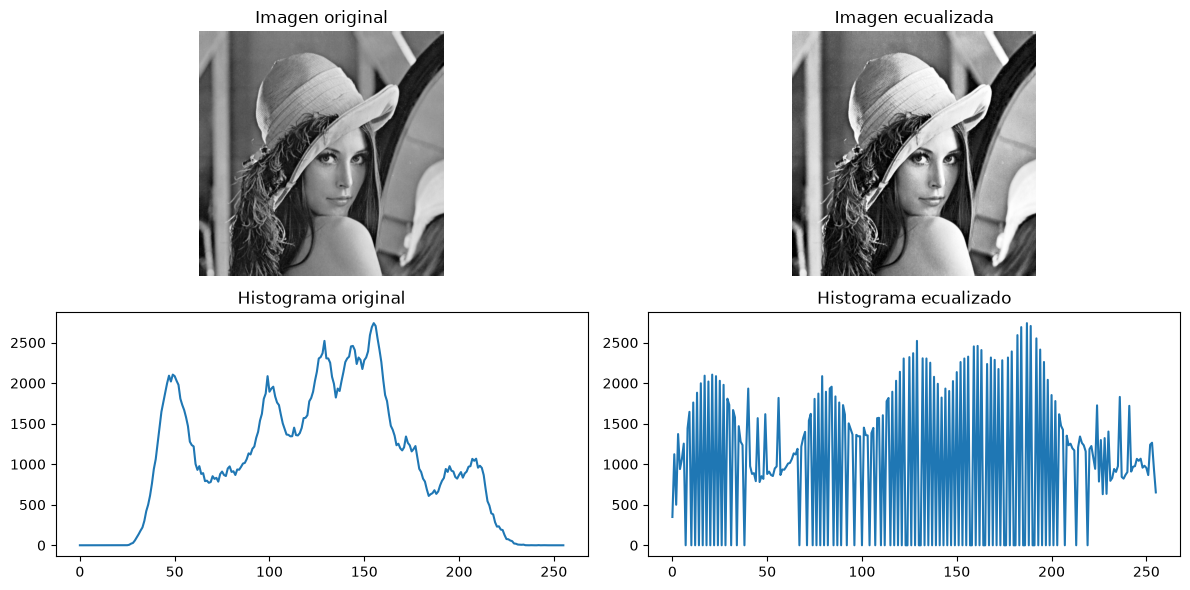

True

In [11]:
# Aplicar ecualización del histograma
imagen_ecualizada = cv2.equalizeHist(imagen_gris)

# Comparar imagen original y ecualizada
plt.figure(figsize=(12, 6))

plt.subplot(2, 2, 1)
plt.imshow(imagen_gris, cmap="gray")
plt.title("Imagen original")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(imagen_ecualizada, cmap="gray")
plt.title("Imagen ecualizada")
plt.axis("off")

# Calcular los histogramas
hist_original = cv2.calcHist([imagen_gris], [0], None, [256], [0, 256])
hist_ecualizado = cv2.calcHist([imagen_ecualizada], [0], None, [256], [0, 256])

plt.subplot(2, 2, 3)
plt.plot(hist_original)
plt.title("Histograma original")

plt.subplot(2, 2, 4)
plt.plot(hist_ecualizado)
plt.title("Histograma ecualizado")

plt.tight_layout()
plt.show()

# Guardar el resultado
cv2.imwrite("resultados/05_ecualizada.png", imagen_ecualizada)

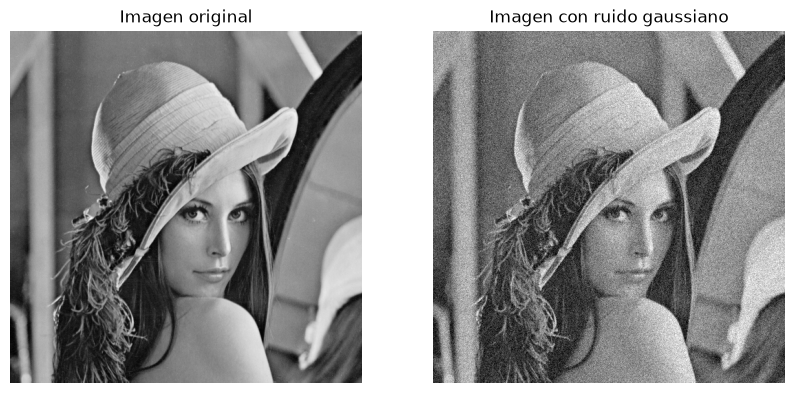

In [12]:
# Convertir la imagen a números decimales
imagen_float = imagen_gris.astype(np.float32)

# Generar ruido gaussiano
ruido = np.random.normal(0, 20, imagen_gris.shape)

# Añadir el ruido a la imagen
imagen_con_ruido = imagen_float + ruido

# Limitar los valores al rango de 0 a 255
imagen_con_ruido = np.clip(imagen_con_ruido, 0, 255)

# Convertir nuevamente a enteros de 8 bits
imagen_con_ruido = imagen_con_ruido.astype(np.uint8)

# Mostrar los resultados
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(imagen_gris, cmap="gray")
plt.title("Imagen original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imagen_con_ruido, cmap="gray")
plt.title("Imagen con ruido gaussiano")
plt.axis("off")

plt.show()

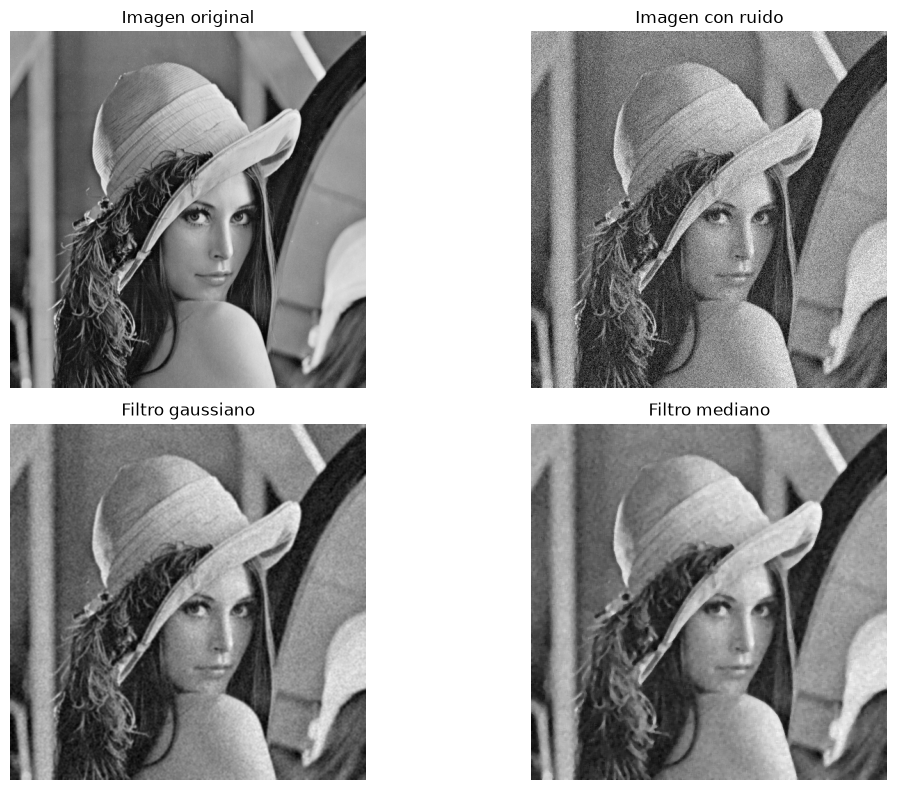

True

In [13]:
# Aplicar filtro gaussiano
imagen_gaussiana = cv2.GaussianBlur(
    imagen_con_ruido,
    (5, 5),
    0
)

# Aplicar filtro mediano
imagen_mediana = cv2.medianBlur(
    imagen_con_ruido,
    5
)

# Mostrar las cuatro imágenes
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(imagen_gris, cmap="gray")
plt.title("Imagen original")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(imagen_con_ruido, cmap="gray")
plt.title("Imagen con ruido")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(imagen_gaussiana, cmap="gray")
plt.title("Filtro gaussiano")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(imagen_mediana, cmap="gray")
plt.title("Filtro mediano")
plt.axis("off")

plt.tight_layout()
plt.show()

# Guardar los resultados
cv2.imwrite("resultados/06_filtro_gaussiano.png", imagen_gaussiana)
cv2.imwrite("resultados/07_filtro_mediano.png", imagen_mediana)